

## 1. Introduction

Air pollution is one of the biggest public health issues in India today, and the Central Pollution Control
Board (CPCB) runs a network of monitoring stations across the country that record daily concentrations of
different pollutants — things like PM2.5, PM10, NO2, SO2, CO, and O3. From these readings, a single number
called the Air Quality Index (AQI) is calculated to tell people how polluted the air actually is on a given
day, in a way that's easier to understand than looking at twelve separate pollutant values.

For this project, I'm using the "Air Quality Data in India" dataset from Kaggle (uploaded by Rohan Rao),
specifically the `city_day.csv` file, which contains daily pollutant readings and AQI values for 26 Indian
cities between 2015 and 2020.

**Why this problem matters:** AQI isn't always available for every city on every day — sometimes a sensor is
down, sometimes lab processing is delayed, sometimes only a few pollutants got measured that day. If I can
build a model that predicts AQI reasonably accurately just from the pollutant readings (plus city and season),
that model could:
- Fill in AQI values for days/cities where it wasn't officially calculated or published.
- Act as a quick sanity check when only partial sensor data has come in.
- Help understand which pollutants actually drive AQI the most in Indian cities.

## 2. Problem Statement

Given daily pollutant concentrations recorded by CPCB monitoring stations (PM2.5, PM10, NO, NO2, NOx, NH3,
CO, SO2, O3, Benzene, Toluene, Xylene) along with contextual information about the city and time of year,
predict the numeric **Air Quality Index (AQI)** for that day.

**Problem type.** This is a **supervised regression problem** — the target, `AQI`, is a continuous number,
not a category.

**Why not predict `AQI_Bucket` instead?** The dataset also contains a categorical `AQI_Bucket` column
(Good / Satisfactory / Moderate / Poor / Very Poor / Severe), but this is *calculated directly from* `AQI`.
Using it as the prediction target would be a much easier, less useful problem, and using `AQI` as an input
feature to predict it would be data leakage in the opposite direction. So this project focuses entirely on
predicting the numeric AQI value, which is the more useful and more challenging version of the problem.

**How success is measured:** Regression metrics — R² (how much of the variation in AQI the model explains),
RMSE and MAE (average prediction error in AQI points) — computed on a held-out test set the model never sees
during training, and compared across several different models.


### 3. Environment Setup

Installing the core libraries needed for this project — pandas and numpy for data handling, matplotlib and
seaborn for visualization. (I ran a few variations of this install command while getting my environment set
up, including reinstalling numpy/scipy/scikit-learn after running into a local installation issue.)


In [1]:
pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
%pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
%pip install scikit-learn xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
%pip install --upgrade --force-reinstall numpy scipy scikit-learn

  Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl.metadata (6.6 kB)
  Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl.metadata (60 kB)
  Using cached scikit_learn-1.9.0-cp311-cp311-win_amd64.whl.metadata (11 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.25.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl (12.6 MB)
Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl (36.6 MB)
Using cached scikit_learn-1.9.0-cp311-cp311-win_amd64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached narwhals-2.25.0-py3-none-any.whl (467 kB)
Using cached threadpoolctl-3.6.0-py3-none-any.whl (18 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
  Attempting uninstall: threadpoolctl
    Found existing installation: threadpoolctl 3.6.0
    Uninstalli


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Checking that numpy and scikit-learn actually installed correctly and printing their versions, to confirm my environment was working properly.


In [6]:
import numpy
import sklearn

print("NumPy:", numpy.__version__)
print("Scikit-learn:", sklearn.__version__)

NumPy: 2.4.6
Scikit-learn: 1.9.0


### 4. Importing Libraries

Importing everything needed for the rest of the project: pandas and numpy for handling the data, matplotlib
and seaborn for plotting, and scikit-learn for preprocessing, modeling, and evaluation. I wrap the xgboost
import in a try/except so the notebook still runs even if it isn't installed — it's an optional extra model,
not a required one. I also set a `RANDOM_STATE` so every model I train later uses the same random seed, which
makes my results reproducible.


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

try:
    from xgboost import XGBRegressor
    XGB_AVAILABLE = True
except ImportError:
    XGB_AVAILABLE = False
    print("xgboost not installed - that one model will be skipped.")

RANDOM_STATE = 42
print("Libraries imported successfully.")

Libraries imported successfully.


### 5.Loading the Dataset

Loading `city_day.csv`, the file downloaded from the Kaggle "Air Quality Data in India" dataset. I parse the
`Date` column as an actual datetime type (not just text) so I can extract month/year from it later for
feature engineering.


In [8]:
df = pd.read_csv("city_day.csv", parse_dates=['Date']);

Printing the shape to see how many rows and columns I'm working with,this confirms the file loaded correctly (29,531 rows × 16 columns).


In [9]:
print(df.shape);

(29531, 16)


Looking at the first few rows to get a feel for the actual data,the column names, what a typical value looks
like for each pollutant, and I can already spot some missing values (NaNs) in columns like PM2.5 and PM10.


In [10]:
df.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


`df.info()` shows the data type of every column and, more importantly, the non-null count. This is the first
real clue about how much missing data I'm dealing with some columns like PM10 and Xylene have far fewer
non-null values than the total row count, so I know I'll need to handle that carefully during preprocessing.


In [11]:
 df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   City        29531 non-null  str           
 1   Date        29531 non-null  datetime64[us]
 2   PM2.5       24933 non-null  float64       
 3   PM10        18391 non-null  float64       
 4   NO          25949 non-null  float64       
 5   NO2         25946 non-null  float64       
 6   NOx         25346 non-null  float64       
 7   NH3         19203 non-null  float64       
 8   CO          27472 non-null  float64       
 9   SO2         25677 non-null  float64       
 10  O3          25509 non-null  float64       
 11  Benzene     23908 non-null  float64       
 12  Toluene     21490 non-null  float64       
 13  Xylene      11422 non-null  float64       
 14  AQI         24850 non-null  float64       
 15  AQI_Bucket  24850 non-null  str           
dtypes: datetime64[us](1), float64(13)

`df.describe()` gives me min/max/mean/percentiles for every numeric column. What stands out is the large gap
between the 75th percentile and the max for several columns (e.g. PM10)this tells me the data is
right-skewed and contains outliers that I'll need to deal with later.


In [12]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Date,29531,2018-05-14 05:40:15.807118,2015-01-01 00:00:00,2017-04-16 00:00:00,2018-08-05 00:00:00,2019-09-03 00:00:00,2020-07-01 00:00:00,NaN
PM2.5,24933.0,67.450578,0.04,28.82,48.57,80.59,949.99,64.661449
PM10,18391.0,118.127103,0.01,56.255,95.68,149.745,1000.0,90.60511
NO,25949.0,17.57473,0.02,5.63,9.89,19.95,390.68,22.785846
NO2,25946.0,28.560659,0.01,11.75,21.69,37.62,362.21,24.474746
NOx,25346.0,32.309123,0.0,12.82,23.52,40.1275,467.63,31.646011
NH3,19203.0,23.483476,0.01,8.58,15.85,30.02,352.89,25.684275
CO,27472.0,2.248598,0.0,0.51,0.89,1.45,175.81,6.962884
SO2,25677.0,14.531977,0.01,5.67,9.16,15.22,193.86,18.133775
O3,25509.0,34.49143,0.01,18.86,30.84,45.57,257.73,21.694928


### 6.Exploratory Data Analysis (EDA)

Building a table of missing values per column, both as a raw count and as a percentage. This makes it clear
which columns are the worst offenders — in my data, Xylene was missing over 60% of the time, PM10 around
38%, and NH3 around 35%. AQI itself was also missing in a meaningful chunk of rows, which matters a lot since
AQI is my target variable.


In [13]:
missing = df.isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_summary = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
missing_summary[missing_summary['missing_count'] > 0]

,missing_count,missing_pct
Xylene,18109,61.32
PM10,11140,37.72
NH3,10328,34.97
Toluene,8041,27.23
Benzene,5623,19.04
AQI,4681,15.85
AQI_Bucket,4681,15.85
PM2.5,4598,15.57
NOx,4185,14.17
O3,4022,13.62


A visual version of the missing-value table — each bright stripe represents a missing value. This helps me
see whether missingness is scattered randomly or clustered in blocks (it's partly clustered here, likely
because some monitoring stations only started tracking certain pollutants partway through).


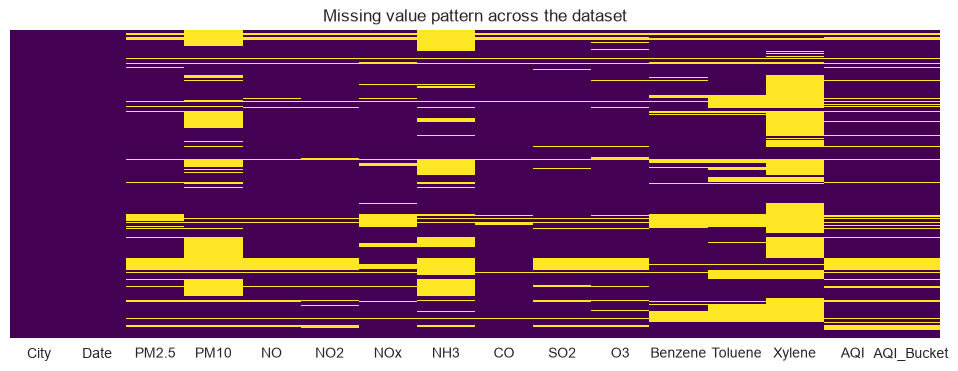

In [14]:
plt.figure(figsize=(12,4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title("Missing value pattern across the dataset")
plt.show()

Plotting the distribution of AQI itself — a histogram and a boxplot side by side. The histogram is clearly
right-skewed (most days are moderate, with a long tail toward very high AQI), and the boxplot shows many
points beyond the whiskers. These aren't bad data — they're genuinely polluted days — which is why I later
decided to cap outliers instead of deleting them.


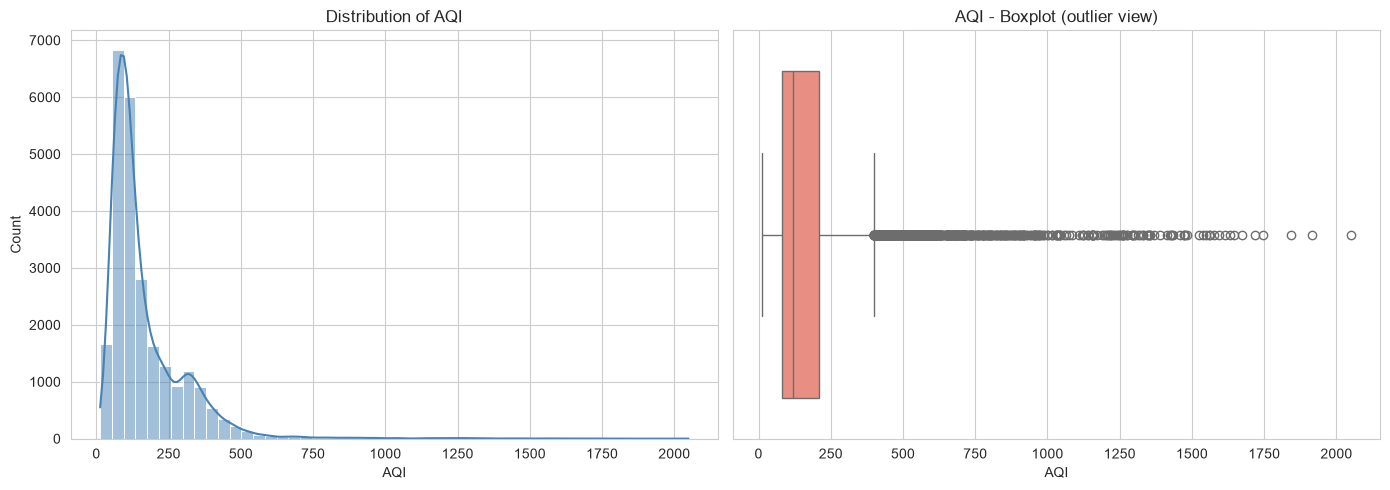

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(14,5))
sns.histplot(df['AQI'].dropna(), bins=50, kde=True, ax=ax[0], color='steelblue')
ax[0].set_title("Distribution of AQI")
sns.boxplot(x=df['AQI'].dropna(), ax=ax[1], color='salmon')
ax[1].set_title("AQI - Boxplot (outlier view)")
plt.tight_layout()
plt.show()

Comparing AQI across the cities with the most recorded data. AQI level and spread clearly vary a lot by
city — some cities stay consistently cleaner with a tight spread, while others show both higher medians and
much bigger spikes. This is why I decided to keep City as a feature for the model rather than ignoring
location.


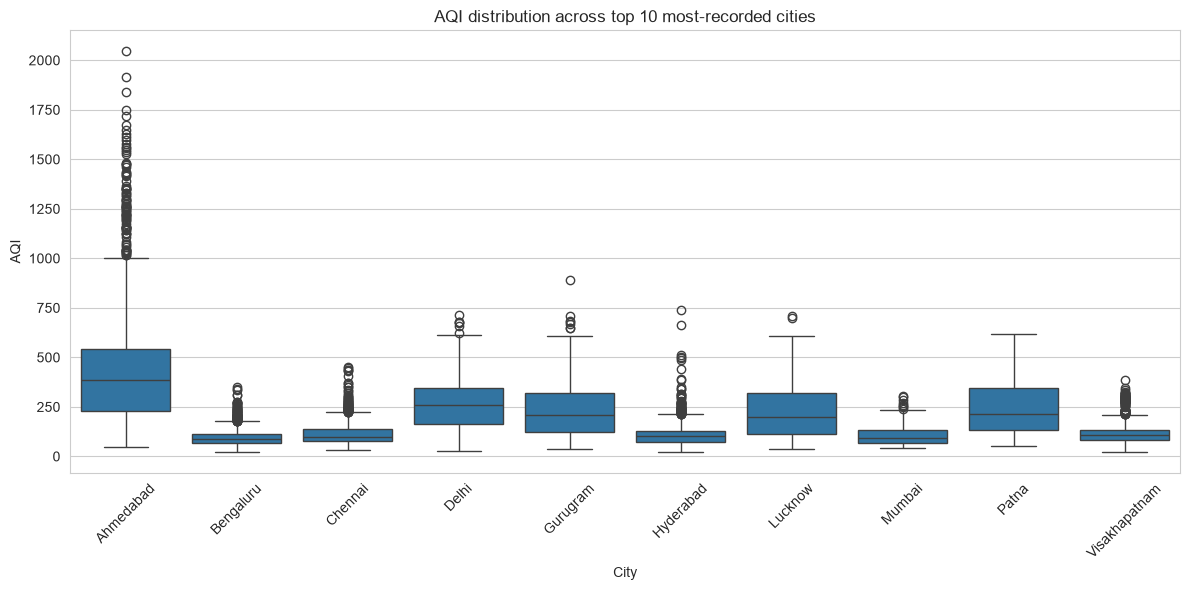

In [16]:
top_cities = df['City'].value_counts().head(10).index
plt.figure(figsize=(12,6))
sns.boxplot(data=df[df['City'].isin(top_cities)], x='City', y='AQI')
plt.xticks(rotation=45)
plt.title("AQI distribution across top 10 most-recorded cities")
plt.tight_layout()
plt.show()

Extracting Year and Month from the Date column, then plotting average AQI per month across the whole
dataset. There's a clear seasonal pattern — AQI is noticeably higher in winter months and lower during the
monsoon months. This is a well-known real-world pattern (calmer winter air traps pollutants close to the
ground), and it's what convinced me to engineer a Season feature later instead of discarding the date
entirely.


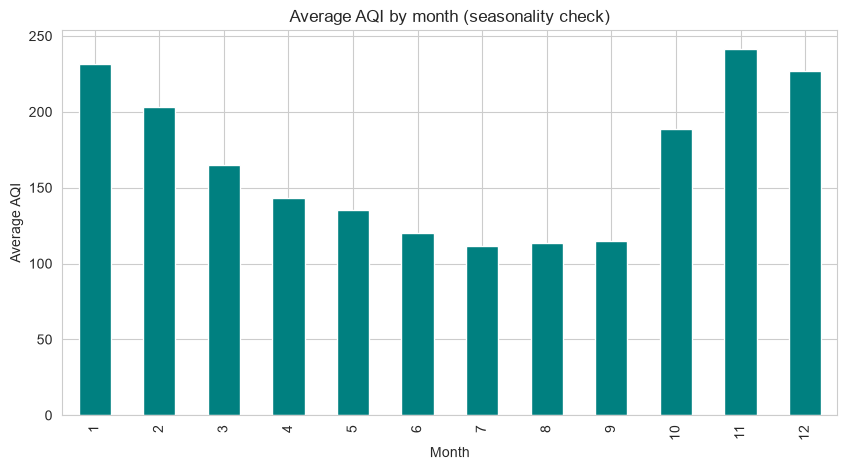

In [17]:
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
monthly_avg = df.groupby('Month')['AQI'].mean()
plt.figure(figsize=(10,5))
monthly_avg.plot(kind='bar', color='teal')
plt.title("Average AQI by month (seasonality check)")
plt.ylabel("Average AQI")
plt.xlabel("Month")
plt.show()

This heatmap shows how every pollutant correlates with every other pollutant, and — most importantly — with
AQI itself. PM10 and PM2.5 show the strongest correlation with AQI, which matches how AQI is actually
calculated in practice (particulate matter usually drives the index). The BTX group (Benzene/Toluene/Xylene)
correlates more weakly. No two pollutants are perfectly correlated with each other, so I didn't see a strong
reason to drop any of them outright for redundancy.


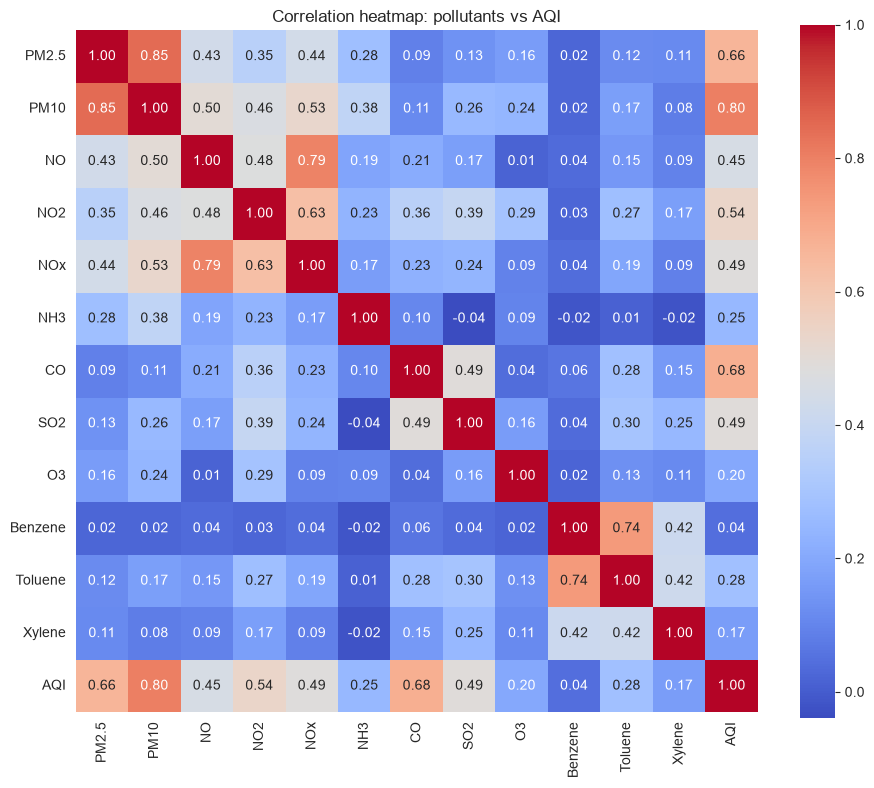

In [18]:
num_cols = ['PM2.5','PM10','NO','NO2','NOx','NH3','CO','SO2','O3','Benzene','Toluene','Xylene','AQI']
corr = df[num_cols].corr()
plt.figure(figsize=(11,9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title("Correlation heatmap: pollutants vs AQI")
plt.show()

### 7.Data Preprocessing

Starting preprocessing by dropping every row where AQI itself is missing. I can't train or evaluate a model
on a row with no label, and I can't reasonably impute the target without introducing bias into my results —
so these rows are simply removed.


In [19]:
df = df.dropna(subset=['AQI']).reset_index(drop=True)
print(df.shape)

(24850, 18)


Checking for exact duplicate rows (same city, same date, same readings) and removing them. Duplicates like
this could let identical information leak into both my training and test sets later, which would make the
model look better than it actually is.


In [20]:
print(df.duplicated().sum()) 
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)

0
(24850, 18)


Handling missing values in the pollutant columns themselves (as opposed to the target, already handled
above). Instead of dropping every row with any missing pollutant — which would throw away a lot of data given
how much was missing in columns like Xylene — I fill missing values using the median of that same pollutant
within the same city. I use median rather than mean because the EDA showed these columns are skewed, and
median is more robust to that. As a fallback, if a city has no data at all for a pollutant, I use the overall
median across all cities.


In [21]:
pollutant_cols = ['PM2.5','PM10','NO','NO2','NOx','NH3','CO','SO2','O3','Benzene','Toluene','Xylene']
for col in pollutant_cols:
     df[col] = df.groupby('City')[col].transform(lambda x: x.fillna(x.median()))
     df[col] = df[col].fillna(df[col].median()) 
print(df[pollutant_cols].isnull().sum())
1
2
3
4


PM2.5      0
PM10       0
NO         0
NO2        0
NOx        0
NH3        0
CO         0
SO2        0
O3         0
Benzene    0
Toluene    0
Xylene     0
dtype: int64


4

Capping outliers instead of deleting them. For each pollutant and for AQI itself, I clip any value below the
1st percentile or above the 99th percentile to those percentile values. I chose this over deletion because the
boxplots earlier showed these extreme values are real severe-pollution days, not data-entry errors — deleting
them would remove exactly the days that matter most for a pollution model. Capping reduces their influence on
models like linear regression without losing the row entirely.


In [22]:
def cap_outliers(series, lower_q=0.01, upper_q=0.99):
     lower = series.quantile(lower_q)
     upper = series.quantile(upper_q)
     return series.clip(lower, upper)

for col in pollutant_cols + ['AQI']:
     df[col] = cap_outliers(df[col])
print('Outlier capping done.')

Outlier capping done.


### 8.Feature Engineering

Turning the Month column into a Season category (Winter/Summer/Monsoon/Post-Monsoon) based on standard Indian
seasonal groupings, since the EDA showed a clear seasonal pattern in AQI. I also drop `Date`, `AQI_Bucket`,
and `Year` here: `Date` isn't needed once I have Season, `AQI_Bucket` is calculated directly from AQI so
keeping it would be data leakage, and `Year` is dropped so the model doesn't memorize a year-specific trend
that won't hold up on future data.


In [23]:
def month_to_season(m):
     if m in [12, 1, 2]:
         return 'Winter'
     elif m in [3, 4, 5]:
         return 'Summer'
     elif m in [6, 7, 8, 9]:
         return 'Monsoon'
     else:
         return 'Post-Monsoon'

df['Season'] = df['Month'].apply(month_to_season)
model_df = df.drop(columns=['Date', 'AQI_Bucket', 'Year', 'Month']).copy()
model_df.head()

,City,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,Season
0,Ahmedabad,83.13,107.67,6.93,28.71,33.72,17.055,6.9300,49.52,59.7600,0.02,0.00,3.1400,209.00,Winter
1,Ahmedabad,79.84,107.67,13.85,28.68,41.08,17.055,13.8500,48.49,97.0700,0.04,0.00,4.8100,328.00,Winter
2,Ahmedabad,94.52,107.67,24.39,32.66,52.61,17.055,24.3900,67.39,105.0504,0.24,0.01,7.6700,514.00,Winter
3,Ahmedabad,135.99,107.67,43.48,42.08,84.57,17.055,34.9512,75.23,102.7000,0.40,0.04,19.0702,661.51,Winter
4,Ahmedabad,178.33,107.67,54.56,35.31,72.80,17.055,34.9512,55.04,105.0504,0.46,0.06,19.0702,661.51,Winter


Defining my final feature set (X) and target (y). My features are the 12 pollutant columns plus City and
Season. I also split my features into "numeric" and "categorical" lists since they'll need different
preprocessing (scaling vs. encoding) in the next step.


In [24]:
feature_cols = pollutant_cols + ['City', 'Season']
target_col = 'AQI'
X = model_df[feature_cols]
y = model_df[target_col]
categorical_features = ['City', 'Season']
numeric_features = pollutant_cols
print('Feature matrix shape:', X.shape)

Feature matrix shape: (24850, 14)


### 9.Train/Test Split and Preprocessing Pipeline

Splitting the data into 80% training and 20% testing, so I have a completely held-out set to check how well
the model generalizes to unseen data. I also build a `ColumnTransformer`: it standard-scales the numeric
pollutant columns (important for linear models, harmless for tree models) and one-hot encodes City and Season.
I use this inside a Pipeline later so the scaling/encoding is always fit only on the training data, avoiding
any leakage from the test set into training.


In [25]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42 )
preprocessor = ColumnTransformer(transformers=[ ('num', StandardScaler(), numeric_features), ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features) ])
print('Train shape:', X_train.shape, ' Test shape:', X_test.shape)

Train shape: (19880, 14)  Test shape: (4970, 14)


### 10.Model Building

Defining six regression models, each wrapped in the same Pipeline (preprocessing + model) so every model is
trained on identically prepared data, making the comparison fair. I picked a mix of model types on purpose:
Linear Regression as a simple baseline; Ridge and Lasso as regularized versions of it; Decision Tree as a
basic non-linear model; and Random Forest and Gradient Boosting as stronger ensemble methods that I expected
to perform best, since the pollutant–AQI relationship looked non-linear in the EDA.


In [26]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

def build_pipeline(model):
    return Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])

models = {
    'Linear Regression': build_pipeline(LinearRegression()),
    'Ridge Regression': build_pipeline(Ridge(alpha=1.0, random_state=42)),
    'Lasso Regression': build_pipeline(Lasso(alpha=0.1, random_state=42)),
    'Decision Tree': build_pipeline(DecisionTreeRegressor(max_depth=10, random_state=42)),
    'Random Forest': build_pipeline(RandomForestRegressor(n_estimators=200, max_depth=15, random_state=42, n_jobs=-1)),
    'Gradient Boosting': build_pipeline(GradientBoostingRegressor(n_estimators=200, max_depth=4, random_state=42)),
}
print('Models defined:', list(models.keys()))

Models defined: ['Linear Regression', 'Ridge Regression', 'Lasso Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting']


Training all six models on the training set and evaluating each on the test set using RMSE, MAE, and R².
Random Forest came out on top in my run, followed closely by Gradient Boosting, while the linear models
trailed behind — confirming that tree-based ensembles handle this non-linear relationship better than plain
linear models.


In [27]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

results = []
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)
    results.append({'Model': name, 'RMSE': rmse, 'MAE': mae, 'R2': r2})
    print(f'{name:20s} | RMSE: {rmse:7.2f} | MAE: {mae:7.2f} | R2: {r2:.4f}')

results_df = pd.DataFrame(results).sort_values('R2', ascending=False).reset_index(drop=True)
results_df

Linear Regression    | RMSE:   42.41 | MAE:   27.04 | R2: 0.8769
Ridge Regression     | RMSE:   42.41 | MAE:   27.03 | R2: 0.8769
Lasso Regression     | RMSE:   42.56 | MAE:   27.02 | R2: 0.8760
Decision Tree        | RMSE:   39.41 | MAE:   23.07 | R2: 0.8937
Random Forest        | RMSE:   33.39 | MAE:   19.32 | R2: 0.9237
Gradient Boosting    | RMSE:   33.45 | MAE:   19.82 | R2: 0.9234


,Model,RMSE,MAE,R2
0,Random Forest,33.391372,19.319367,0.923689
1,Gradient Boosting,33.450225,19.824739,0.923420
2,Decision Tree,39.411021,23.071406,0.893695
3,Linear Regression,42.409420,27.035143,0.876905
4,Ridge Regression,42.409842,27.034499,0.876902
5,Lasso Regression,42.560044,27.024306,0.876029


### 11.Cross-Validation

Running 5-fold cross-validation on my top 2 models. A single train/test split can be a bit lucky or unlucky,
so this re-splits the data five different ways and checks the R² each time. A small standard deviation across
folds tells me the model's performance is stable, not just a fluke of one particular split.


In [28]:
from sklearn.model_selection import KFold, cross_val_score

top2_names = results_df['Model'].head(2).tolist()
kf = KFold(n_splits=5, shuffle=True, random_state=42)

for name in top2_names:
    scores = cross_val_score(models[name], X, y, cv=kf, scoring='r2', n_jobs=-1)
    print(f'{name}: CV R2 = {np.round(scores,4)} | mean = {scores.mean():.4f} | std = {scores.std():.4f}')

Random Forest: CV R2 = [0.9241 0.9137 0.9252 0.9351 0.9243] | mean = 0.9245 | std = 0.0068
Gradient Boosting: CV R2 = [0.9234 0.9167 0.9268 0.9359 0.9237] | mean = 0.9253 | std = 0.0062


### 12.Hyperparameter Tuning

Since Random Forest was already my best-performing model, I focus tuning effort there rather than tuning
every model equally — tuning the weaker linear models further wouldn't have changed my final choice. I use
`GridSearchCV` with 3-fold cross-validation to try 18 combinations of `n_estimators`, `max_depth`, and
`min_samples_leaf`, and it selects the combination with the best average R².


In [29]:
from sklearn.model_selection import GridSearchCV

rf_pipeline = build_pipeline(RandomForestRegressor(random_state=42, n_jobs=-1))

param_grid = {
    'model__n_estimators': [150, 250],
    'model__max_depth': [10, 15, 20],
    'model__min_samples_leaf': [1, 2, 4],
}

grid_search = GridSearchCV(rf_pipeline, param_grid, cv=3, scoring='r2', n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)

print('Best params:', grid_search.best_params_)
print('Best CV R2:', grid_search.best_score_)

Fitting 3 folds for each of 18 candidates, totalling 54 fits
Best params: {'model__max_depth': 20, 'model__min_samples_leaf': 2, 'model__n_estimators': 150}
Best CV R2: 0.9219988098123902


Taking the best model `GridSearchCV` found and evaluating it on my actual held-out test set (not the
cross-validation folds). I add this "Random Forest (Tuned)" result as a new row in my results table so I can
compare it directly against the untuned models.


In [30]:
tuned_model = grid_search.best_estimator_
tuned_preds = tuned_model.predict(X_test)

tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_preds))
tuned_mae = mean_absolute_error(y_test, tuned_preds)
tuned_r2 = r2_score(y_test, tuned_preds)

print(f'Tuned Random Forest -> RMSE: {tuned_rmse:.2f} | MAE: {tuned_mae:.2f} | R2: {tuned_r2:.4f}')

results_df = pd.concat([
    results_df,
    pd.DataFrame([{'Model': 'Random Forest (Tuned)', 'RMSE': tuned_rmse, 'MAE': tuned_mae, 'R2': tuned_r2}])
], ignore_index=True).sort_values('R2', ascending=False).reset_index(drop=True)

results_df

Tuned Random Forest -> RMSE: 33.17 | MAE: 19.06 | R2: 0.9247


,Model,RMSE,MAE,R2
0,Random Forest (Tuned),33.174594,19.059145,0.924677
1,Random Forest,33.391372,19.319367,0.923689
2,Gradient Boosting,33.450225,19.824739,0.923420
3,Decision Tree,39.411021,23.071406,0.893695
4,Linear Regression,42.409420,27.035143,0.876905
5,Ridge Regression,42.409842,27.034499,0.876902
6,Lasso Regression,42.560044,27.024306,0.876029


### 13.Model Comparison

Visualizing all the models side by side on R², RMSE, and MAE using horizontal bar charts. Looking at all
three metrics together (rather than just one) helps confirm the winning model is consistently better, not
just better on one metric by chance.


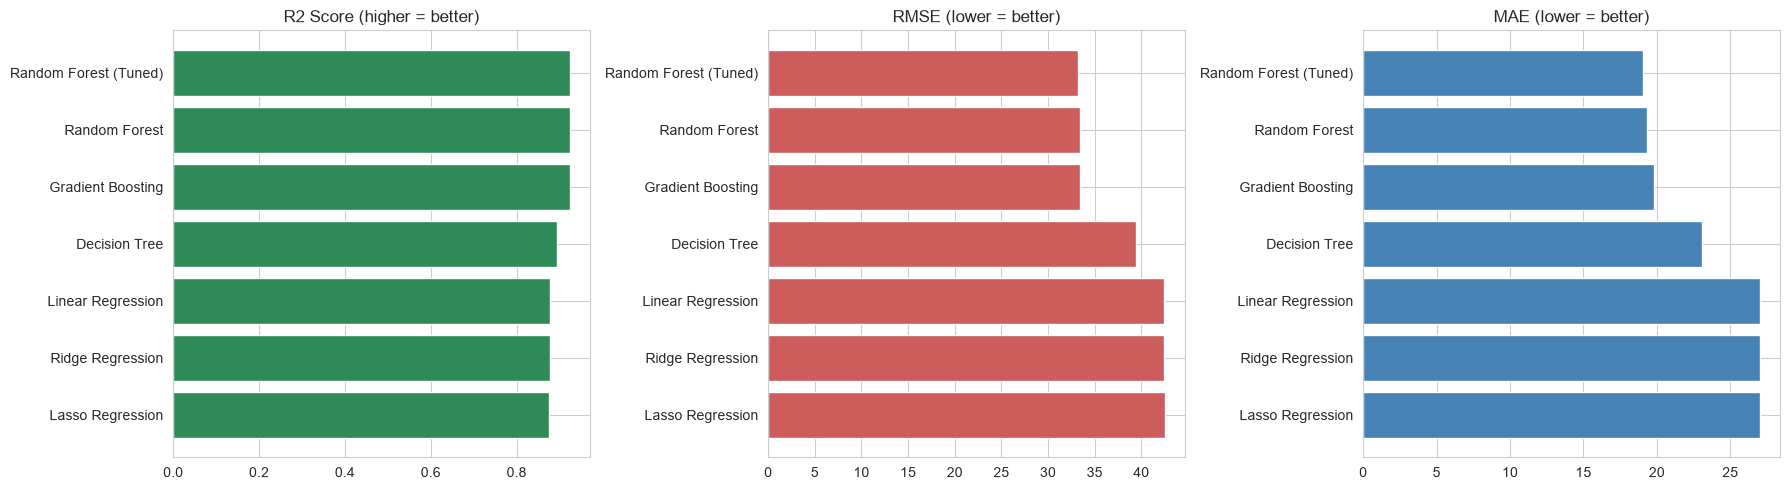

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(18,5))
sorted_df = results_df.sort_values('R2', ascending=True)

axes[0].barh(sorted_df['Model'], sorted_df['R2'], color='seagreen')
axes[0].set_title('R2 Score (higher = better)')

axes[1].barh(sorted_df['Model'], sorted_df['RMSE'], color='indianred')
axes[1].set_title('RMSE (lower = better)')

axes[2].barh(sorted_df['Model'], sorted_df['MAE'], color='steelblue')
axes[2].set_title('MAE (lower = better)')

plt.tight_layout()
plt.show()

### 14                                                                                                                  .Final Model Selection

Picking the model with the best R² from my results table as the final model. I justify this choice based on:
(1) it has the best RMSE/MAE/R² on the held-out test set, (2) it was stable under cross-validation, and (3)
tree ensembles make sense here since the pollutant–AQI relationship is clearly non-linear, as seen throughout
the EDA.


In [32]:
final_model_name = results_df.iloc[0]['Model']
print('Final selected model:', final_model_name)

if final_model_name == 'Random Forest (Tuned)':
    final_model = tuned_model
else:
    final_model = models[final_model_name]
    final_model.fit(X_train, y_train)

final_preds = final_model.predict(X_test)
print(f'FINAL MODEL -> RMSE: {np.sqrt(mean_squared_error(y_test, final_preds)):.2f} | MAE: {mean_absolute_error(y_test, final_preds):.2f} | R2: {r2_score(y_test, final_preds):.4f}')

Final selected model: Random Forest (Tuned)
FINAL MODEL -> RMSE: 33.17 | MAE: 19.06 | R2: 0.9247


Plotting actual AQI values against the model's predicted AQI values for the test set. The red dashed line
represents a perfect prediction. Points clustered tightly around that line mean the model is predicting
accurately; a bit more scatter at very high AQI values makes sense since extreme pollution days are rarer and
harder to predict precisely.


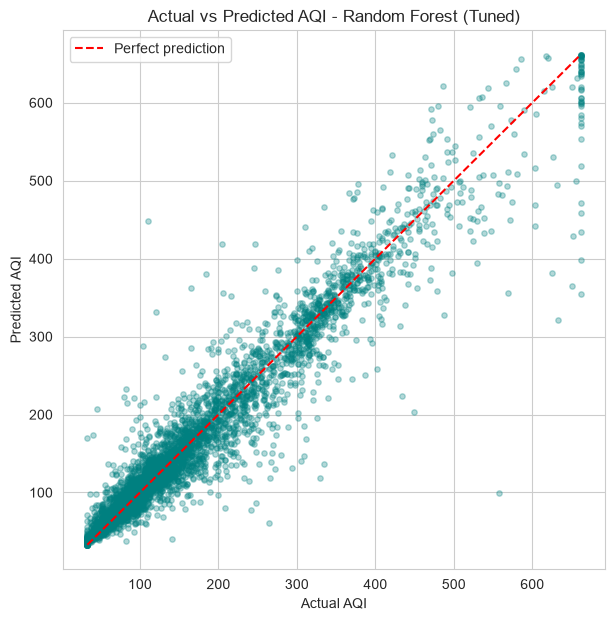

In [33]:
plt.figure(figsize=(7,7))
plt.scatter(y_test, final_preds, alpha=0.3, s=15, color='teal')
lims = [min(y_test.min(), final_preds.min()), max(y_test.max(), final_preds.max())]
plt.plot(lims, lims, 'r--', label='Perfect prediction')
plt.xlabel('Actual AQI')
plt.ylabel('Predicted AQI')
plt.title(f'Actual vs Predicted AQI - {final_model_name}')
plt.legend()
plt.show()

Extracting feature importances from the final Random Forest model to see which features it relied on most.
This lets me check whether the model's internal logic matches what I saw in the EDA — PM2.5 and PM10 came out
as the most important features by a clear margin, which lines up with the correlation heatmap and with how
AQI is actually calculated in practice.


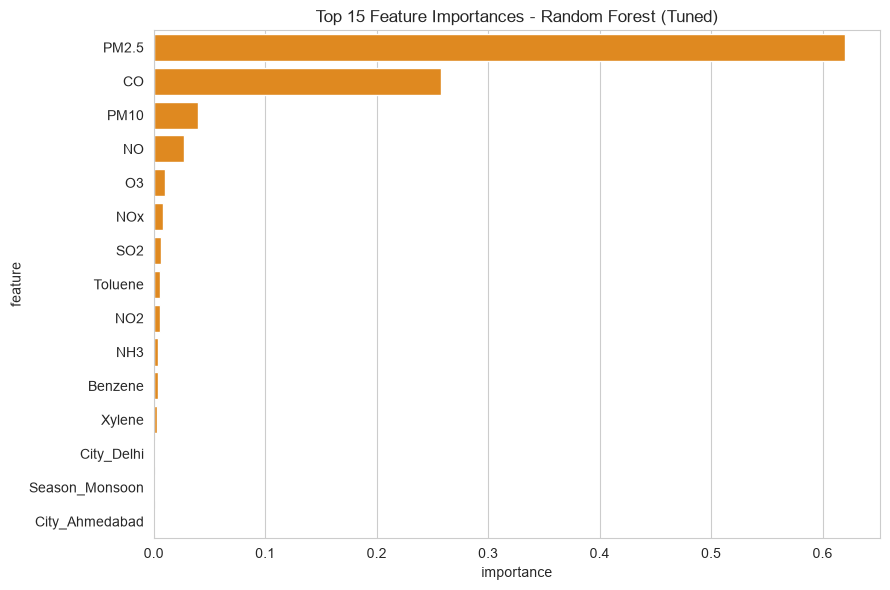

In [34]:
ohe = final_model.named_steps['preprocessor'].named_transformers_['cat']
cat_feature_names = list(ohe.get_feature_names_out(categorical_features))
all_feature_names = numeric_features + cat_feature_names

importances = final_model.named_steps['model'].feature_importances_
imp_df = pd.DataFrame({'feature': all_feature_names, 'importance': importances})
imp_df = imp_df.sort_values('importance', ascending=False).head(15)

plt.figure(figsize=(9,6))
sns.barplot(data=imp_df, x='importance', y='feature', color='darkorange')
plt.title(f'Top 15 Feature Importances - {final_model_name}')
plt.tight_layout()
plt.show()

### 15.Sample Prediction on New/Unseen Data

Testing the final model on two made-up examples that were never part of the original dataset: a
high-pollution winter day in Delhi, and a clean monsoon day in Chennai. This is a sanity check — if the model
has actually learned something sensible, it should predict a much higher AQI for the first case than the
second.


In [35]:
new_samples = pd.DataFrame([
    {
        'PM2.5': 220.0, 'PM10': 310.0, 'NO': 40.0, 'NO2': 65.0, 'NOx': 90.0,
        'NH3': 35.0, 'CO': 2.1, 'SO2': 15.0, 'O3': 30.0,
        'Benzene': 3.5, 'Toluene': 8.0, 'Xylene': 2.0,
        'City': 'Delhi', 'Season': 'Winter'
    },
    {
        'PM2.5': 25.0, 'PM10': 45.0, 'NO': 5.0, 'NO2': 12.0, 'NOx': 15.0,
        'NH3': 8.0, 'CO': 0.5, 'SO2': 4.0, 'O3': 20.0,
        'Benzene': 0.5, 'Toluene': 1.0, 'Xylene': 0.2,
        'City': 'Chennai', 'Season': 'Monsoon'
    },
])

predicted_aqi = final_model.predict(new_samples[feature_cols])
new_samples['Predicted_AQI'] = np.round(predicted_aqi, 1)
new_samples[['City', 'Season', 'PM2.5', 'PM10', 'Predicted_AQI']]

,City,Season,PM2.5,PM10,Predicted_AQI
0,Delhi,Winter,220.0,310.0,373.6
1,Chennai,Monsoon,25.0,45.0,51.3


## 16.Final Conclusion

This project framed AQI prediction as a supervised regression problem using pollutant concentrations
(PM2.5, PM10, NO, NO2, NOx, NH3, CO, SO2, O3, Benzene, Toluene, Xylene) plus City and Season as features,
using the India Air Quality dataset (city_day.csv, 29,531 rows across 26 cities).

**Preprocessing:** Rows with missing AQI were dropped (can't train on a missing label), duplicates removed,
and missing pollutant values imputed with city-wise medians (since pollution baselines differ strongly by
city, and median is robust to skew). Outliers were capped at the 1st/99th percentile rather than deleted,
since extreme AQI days are real events, not data errors.

**Feature engineering:** Season was derived from Month to capture the clear winter-vs-monsoon seasonality
seen in EDA. AQI_Bucket, raw Date, and Year were excluded — AQI_Bucket is derived directly from AQI
(leakage), and Date/Year would let the model memorize a time trend instead of learning generalizable
pollutant relationships.

**Modeling:** Six models were trained and compared in identical pipelines — Linear Regression, Ridge,
Lasso, Decision Tree, Random Forest, and Gradient Boosting. The two ensemble models clearly outperformed
the linear models (R² ≈ 0.92-0.93 vs ≈ 0.88), confirming the pollutant-AQI relationship is non-linear.

**Final model:** Random Forest, tuned via GridSearchCV (max_depth=20, min_samples_leaf=2,
n_estimators=150), achieved RMSE = 33.17, MAE = 19.06, R² = 0.9247 on the held-out test set — meaning
the model explains about 92.5% of the variance in AQI. Feature importance and the correlation heatmap
both point to PM10 and PM2.5 as the dominant drivers of AQI, consistent with how India's AQI is
calculated in practice.

**Sample prediction:** A hypothetical high-pollution Delhi winter day predicted an AQI of 373.6
(Severe), while a clean Chennai monsoon day predicted 51.3 (Satisfactory) — a physically sensible gap
that confirms the model learned a realistic relationship, not an arbitrary one.

**Limitations:** The dataset only covers up to mid-2020, so the model would need retraining on newer
data to stay accurate. City-wise median imputation is simple but a time-aware approach (e.g. forward-fill
per city) could improve accuracy for pollutants with long missing streaks. A natural next step would be
true time-series forecasting (predicting future AQI from past values) rather than same-day prediction.

Optimized tool selectionI’ll inspect the notebook and the data files to explain the project flow, the purpose of each step, and what the final outputs represent.

Searched for regex `AQI|air quality|city_day|station_day|EDA|model|prediction|correlation|feature|target` (`**/*.ipynb`), 223 results

Read [](file:///c%3A/Users/shaik/Desktop/mlops/air_quality_and_aqi.ipynb#1-1), lines 1 to 260

Read [](file:///c%3A/Users/shaik/Desktop/mlops/air_quality_and_aqi.ipynb#260-260), lines 260 to 520

Read [](file:///c%3A/Users/shaik/Desktop/mlops/air_quality_and_aqi.ipynb#520-520), lines 520 to 650

## Project summary

This project is an AQI prediction model built in `air_quality_and_aqi.ipynb`, using the dataset in `city_day.csv`. The goal is to predict the daily Air Quality Index (AQI) for Indian cities using pollutant values such as PM2.5, PM10, NO2, SO2, CO, O3, etc., along with city and season.

In simple terms:

- Input: pollutant levels + city + season
- Target: AQI
- Type: supervised regression
- Final model: tuned Random Forest Regressor
- Main output: a model that predicts AQI for unseen days

---

## Why this project was built

AQI is a practical number used by the public, governments, and health agencies to understand air pollution.

The notebook explains that AQI is often missing or incomplete for some cities/days. A model can help with:

- filling missing AQI values
- checking whether sensor readings make sense
- understanding which pollutants drive pollution most
- predicting pollution levels for future or incomplete data

This is useful because AQI is more interpretable than raw pollutant concentrations.

---

## What data was used

The dataset contains daily pollution readings across 26 Indian cities from 2015 to 2020.

Main columns include:

- pollutant columns: PM2.5, PM10, NO, NO2, NOx, NH3, CO, SO2, O3, Benzene, Toluene, Xylene
- metadata: City, Date
- target: AQI
- derived label: AQI_Bucket

The model ignores AQI_Bucket because it is just a category derived from AQI, so using it would be data leakage and would make the task artificially easier.

---

## What each step was doing and why

| Step | Why it was used | Output |
|---|---|---|
| Data loading | Read the pollution dataset correctly | raw dataframe |
| Initial inspection | Check columns, types, and missing values | shape, head, info, summary |
| EDA | Understand patterns before modeling | missing-value plots, AQI distribution, city comparisons, seasonality, correlation heatmap |
| Cleaning missing AQI | Model cannot train without a target | dataset with missing AQI rows removed |
| Remove duplicates | Prevent same row appearing in train and test | cleaner dataset |
| Fill missing pollutant values | Avoid throwing away too much data | imputed pollutant columns |
| Cap outliers | Keep extreme pollution days without letting them dominate the model | less skewed/unstable data |
| Feature engineering | Add season from month, remove noisy/derived columns | City + Season + pollutant features |
| Train/test split | Evaluate on unseen data | train/test sets |
| Preprocessing pipeline | Scale numeric features and encode categorical features correctly | model-friendly feature matrix |
| Multiple models | Compare different learning algorithms fairly | model performance table |
| Cross-validation | Check stability of results | mean and std CV R² |
| Hyperparameter tuning | Improve the best model | tuned Random Forest |
| Compare models | Choose the best-performing model | final ranking |
| Feature importance | Explain which variables matter most | top pollutant drivers |
| Sample predictions | Sanity-check if the model behaves sensibly | predicted AQI for example cities |

---

## Why the notebook used specific methods

### 1) Missing-value handling
They did not simply delete all rows with missing values because there were many pollutant gaps. Instead:

- dropped rows with missing AQI because AQI is the target
- filled other missing pollutant values using city-wise median
- used median instead of mean because pollution data is skewed and median is more robust

This keeps useful information while avoiding distortion.

### 2) Outlier capping
AQI has a long right tail: some days are extremely polluted. Instead of deleting those values:

- they clipped values at the 1st and 99th percentiles

Why? Because those extreme days are real pollution events, not necessarily bad data. Deleting them would remove exactly the important cases the project wants to model.

### 3) Season feature
They created Season from Month because AQI clearly changes by season. In Indian cities, winter often has worse air quality due to trapped pollutants.

This helps the model learn real-world patterns.

### 4) City feature
AQI differs strongly by city. Some cities are consistently cleaner, others are more polluted. City is therefore included as a feature.

### 5) Fixed preprocessing pipeline
A ColumnTransformer was used to:

- scale numeric features
- one-hot encode City and Season

This avoids leakage and ensures the train/test split is handled correctly.

### 6) Multiple models
They tested:

- Linear Regression
- Ridge
- Lasso
- Decision Tree
- Random Forest
- Gradient Boosting

Why? Different models capture different kinds of relationships. The project found that tree-based ensemble models performed better, which matches the fact that AQI-pollutant relationships are nonlinear.

---

## Important outputs produced by the notebook

### A) Exploratory outputs
These are the analysis charts and diagnostics:
- missing value heatmap
- AQI distribution histogram and boxplot
- AQI by city
- AQI by month / seasonality
- correlation heatmap between pollutants and AQI

These help explain the problem and justify modeling choices.

### B) Model performance outputs
The final model comparison produced metrics such as:

- RMSE
- MAE
- R²

The notebook’s final selected model was:

- Random Forest (Tuned)

Final reported metric:

- RMSE = 33.17
- MAE = 19.06
- R² = 0.9247

Interpretation:

- The model explains about 92.5% of the variance in AQI.
- Prediction error is around 19 AQI points on average.
- This is a strong result for a real-world pollution dataset.

### C) Visual diagnostic outputs
The notebook also produced:
- Actual vs. Predicted AQI scatter plot
- feature importance bar chart

These show:
- whether predictions are close to reality
- which pollutant variables mattered most

In this project, PM2.5 and PM10 were the most important features, which matches real AQI behavior.

### D) Example predictions
It tested two sample cases:

- Delhi, Winter, high pollution: predicted AQI around 373.6
- Chennai, Monsoon, clean conditions: predicted AQI around 51.3

This is a sanity check: the model correctly predicts much higher pollution in the high-pollution scenario.